# Qwen3.5 Audit v11 Segmentation, Taxonomy Extraction, Spec Eval, and LLM Judge

This notebook runs the three Qwen segmentation prompts over all `audit_v11` clips, extracts each free-form output into the constrained timestamped taxonomy, evaluates the extracted predictions with `specs/eval_spec.md`, and runs LLM judge evaluation on both original segmentation text and extracted JSON. Reusable logic is in `src/cvs_act/action_segment_eval.py`.

In [1]:

from openai import OpenAI
import hashlib
import json
import os
import sys
import time
from pathlib import Path
from statistics import mean

try:
    import pandas as pd
except Exception:
    pd = None

ROOT_DIR = Path('/mnt/md0/weiqiuy/surgent')
SRC_DIR = ROOT_DIR / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from cvs_act.action_segment_eval import (
    ACTORS,
    build_deterministic_structured_extraction,
    build_extraction_prompt,
    build_messages_for_record,
    build_judge_prompt,
    build_simple_options,
    convert_record_to_simple_actions,
    default_segmentation_prompts,
    evaluate_method_predictions,
    extract_json_object,
    load_audit_records,
    naturalize_simple_actions,
    is_deterministic_structured_method,
    normalize_extraction,
    read_json,
    segmentation_source_method,
    write_json,
)

with open('/mnt/md0/weiqiuy/ips/carnaroli.txt') as input_file:
    carnaroli_ip = input_file.read().strip()
client = OpenAI(base_url=f'http://{carnaroli_ip}:8001/v1', api_key=os.environ['OPENAI_API_KEY'])

MODEL_ID = 'Qwen/Qwen3.6-35B-A3B-FP8'
REQUEST_TEMPERATURE = 0
REQUEST_ENABLE_THINKING = False
ANNOTATION_ROOT = ROOT_DIR / 'data/processed/CVS_Challenge_SAGES_v1/cvs_act_annotations/v1'
AUDIT_V11_DIR = ANNOTATION_ROOT / 'audit_v11'
FRAMES_DIR = ROOT_DIR / 'data/processed/CVS_Challenge_SAGES_v1/frames/test'
SPEC_PATH = ANNOTATION_ROOT / 'specs/eval_spec.md'
ARTIFACT_DIR = ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval'
SEGMENT_CACHE_PATH = ARTIFACT_DIR / 'segment_cache.json'
EXTRACTION_CACHE_PATH = ARTIFACT_DIR / 'extraction_cache.json'
JUDGE_CACHE_PATH = ARTIFACT_DIR / 'judge_cache.json'
RESULTS_PATH = ARTIFACT_DIR / 'results.json'
SPEC_EVAL_PATH = ARTIFACT_DIR / 'spec_eval_results.json'
JUDGE_SUMMARY_PATH = ARTIFACT_DIR / 'judge_summary.json'

FORCE_SEGMENT = False
FORCE_EXTRACTION = False
FORCE_JUDGE = False
DEBUG_RUN = False
DEBUG_RECORD_LIMIT = 5
MAX_RECORDS = None
WRITE_DERIVED_ARTIFACTS = True
HYDRATE_RESULTS_FROM_CACHES = True
RETRY_ERROR_RESULTS = False
METHODS = ['description_only', 'hint_questions', 'structured_prediction', 'structured_prediction_deterministic']
LABELING_VERSION = 'code_labels_v3'

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print('model:', MODEL_ID)
print('spec:', SPEC_PATH)
print('artifacts:', ARTIFACT_DIR)


model: Qwen/Qwen3.6-35B-A3B-FP8
spec: /mnt/md0/weiqiuy/surgent/data/processed/CVS_Challenge_SAGES_v1/cvs_act_annotations/v1/specs/eval_spec.md
artifacts: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval


In [2]:

records = load_audit_records(AUDIT_V11_DIR)
if DEBUG_RUN:
    records = records[:DEBUG_RECORD_LIMIT]
elif MAX_RECORDS:
    records = records[:MAX_RECORDS]

gt_simple_records = [convert_record_to_simple_actions(record) for record in records]
natural_gt_simple_records = [naturalize_simple_actions(record) for record in gt_simple_records]
simple_options = build_simple_options(gt_simple_records, ANNOTATION_ROOT)
if WRITE_DERIVED_ARTIFACTS or not (ARTIFACT_DIR / 'audit_v11_simple_actions.json').exists():
    write_json(ARTIFACT_DIR / 'audit_v11_simple_actions.json', gt_simple_records)
if WRITE_DERIVED_ARTIFACTS or not (ARTIFACT_DIR / 'audit_v11_simple_actions_natural_language.json').exists():
    write_json(ARTIFACT_DIR / 'audit_v11_simple_actions_natural_language.json', natural_gt_simple_records)
if WRITE_DERIVED_ARTIFACTS or not (ARTIFACT_DIR / 'audit_v11_simple_action_options.json').exists():
    write_json(ARTIFACT_DIR / 'audit_v11_simple_action_options.json', simple_options)

prompts = default_segmentation_prompts(simple_options)
print('records:', len(records))
print('methods:', METHODS)
print('left options:', simple_options['left_retraction_direction_code_options'])
right_triplets = simple_options['right_triplet_options']
print('right tool_type options:', sorted({row[0] for row in right_triplets}))
print('right action_code options:', sorted({row[1] for row in right_triplets}))
print('right target_structure options:', sorted({row[2] for row in right_triplets}))
print('right target contexts:', simple_options['interface_options']['target_context'])
print('camera options:', simple_options['camera_action_code_options'])
print('other options:', simple_options['other_action_code_options'])


records: 90
methods: ['description_only', 'hint_questions', 'structured_prediction']
left options: ['KEEP_RETRACT_LATERAL', 'KEEP_RETRACT_MEDIAL', 'KEEP_RETRACT_UPWARD', 'RETRACT_LATERAL', 'RETRACT_LATERAL_TO_MEDIAL', 'RETRACT_LATERAL_TO_UPWARD', 'RETRACT_MEDIAL', 'RETRACT_MEDIAL_TO_LATERAL', 'RETRACT_UPWARD_TO_LATERAL']
right tool_type options: ['Hook', 'Irrigator', 'Maryland', 'Scissors', 'clipper']
right action_code options: ['CLIP', 'COAGULATE_HEMOSTASIS', 'COUNTERTRACTION_ASSIST', 'DISSECT', 'IRRIGATOR_ASPIRATE', 'RETRACT_DOWNWARD', 'TOOL_WITHDRAW_UNBLOCKS_VIEW', 'sweeping']
right target_structure options: ['CysticArtery', 'CysticDuct', 'CysticPlate', 'GallbladderNeck_Infundibulum', 'HepatocysticTriangle']
right target contexts: ['between presumed cystic duct and presumed cystic artery', 'between cystic artery and cystic plate', 'near the base of the hepatocystic triangle', 'between cystic artery and liver bed', 'moving from a posterior view to an anterior view', 'close to the gal

In [3]:

def cache_get(path, default=None):
    return read_json(path, default if default is not None else {})


def cache_set(path, obj):
    write_json(path, obj)


def model_json_call(messages, cache_path, cache_key, signature, *, force=False, repair_label=None):
    cache = cache_get(cache_path, {})
    entry = cache.get(cache_key)
    if force or not entry or entry.get('signature') != signature:
        response = client.chat.completions.create(
            model=MODEL_ID,
            messages=messages,
            temperature=REQUEST_TEMPERATURE,
            extra_body={'chat_template_kwargs': {'enable_thinking': REQUEST_ENABLE_THINKING}},
        )
        answer_raw = response.choices[0].message.content
        try:
            answer_json = extract_json_object(answer_raw)
            parse_error = None
        except Exception as exc:
            parse_error = repr(exc)
            malformed_path = ARTIFACT_DIR / f'malformed_{repair_label or "json"}_{cache_key.replace("/", "_").replace("::", "__")}.txt'
            malformed_path.write_text(answer_raw)
            repair_messages = [
                {'role': 'system', 'content': 'Repair malformed JSON. Return valid JSON only.'},
                {'role': 'user', 'content': f'Parse error: {parse_error}\n\nMalformed output:\n{answer_raw}'},
            ]
            repair_response = client.chat.completions.create(
                model=MODEL_ID,
                messages=repair_messages,
                temperature=0,
                extra_body={'chat_template_kwargs': {'enable_thinking': REQUEST_ENABLE_THINKING}},
            )
            repaired_raw = repair_response.choices[0].message.content
            (ARTIFACT_DIR / f'repaired_{repair_label or "json"}_{cache_key.replace("/", "_").replace("::", "__")}.txt').write_text(repaired_raw)
            answer_json = extract_json_object(repaired_raw)
        entry = {'answer_raw': answer_raw, 'answer_json': answer_json, 'signature': signature, 'parse_error_repaired': parse_error}
        cache[cache_key] = entry
        cache_set(cache_path, cache)
    return entry


def run_segmentation(record, method_name):
    messages, prompt_record = build_messages_for_record(
        record,
        prompts[segmentation_source_method(method_name)],
        FRAMES_DIR,
        MODEL_ID,
        REQUEST_TEMPERATURE,
        REQUEST_ENABLE_THINKING,
    )
    prompt_method = segmentation_source_method(method_name)
    prompt_record['method'] = prompt_method
    signature = hashlib.sha256(json.dumps(prompt_record, sort_keys=True).encode('utf-8')).hexdigest()
    cache_key = f'{record["example_id"]}::{prompt_method}'
    cache = cache_get(SEGMENT_CACHE_PATH, {})
    entry = cache.get(cache_key)
    if FORCE_SEGMENT or not entry or entry.get('signature') != signature:
        response = client.chat.completions.create(
            model=MODEL_ID,
            messages=messages,
            temperature=REQUEST_TEMPERATURE,
            extra_body={'chat_template_kwargs': {'enable_thinking': REQUEST_ENABLE_THINKING}},
        )
        entry = {'answer_raw': response.choices[0].message.content, 'prompt_record': prompt_record, 'signature': signature}
        cache[cache_key] = entry
        cache_set(SEGMENT_CACHE_PATH, cache)
    return entry


def run_extraction(record, method_name, segmentation_entry):
    frame_range = [int(record['coarse']['start_frame']), int(record['coarse']['end_frame'])]
    cache_key = f'{record["example_id"]}::{method_name}'
    if is_deterministic_structured_method(method_name):
        answer_json = build_deterministic_structured_extraction(method_name, segmentation_entry['answer_raw'], frame_range[0], frame_range[1])
        signature = hashlib.sha256(json.dumps({'run_id': 'structured_prediction_deterministic_extraction_v1', 'segmentation_signature': segmentation_entry.get('signature'), 'answer_json': answer_json}, sort_keys=True).encode('utf-8')).hexdigest()
        cache = cache_get(EXTRACTION_CACHE_PATH, {})
        entry = cache.get(cache_key)
        if FORCE_EXTRACTION or not entry or entry.get('signature') != signature:
            entry = {'answer_raw': json.dumps(answer_json, indent=2), 'answer_json': answer_json, 'signature': signature}
    else:
        prompt = build_extraction_prompt(record['example_id'], frame_range, method_name, segmentation_entry['answer_raw'], simple_options)
        signature = hashlib.sha256(json.dumps({'run_id': 'taxonomy_extraction_v1', 'model': MODEL_ID, 'prompt': prompt}, sort_keys=True).encode('utf-8')).hexdigest()
        entry = model_json_call(
            [
                {'role': 'system', 'content': 'Extract constrained timestamped surgical actions. Return valid JSON only.'},
                {'role': 'user', 'content': prompt},
            ],
            EXTRACTION_CACHE_PATH,
            cache_key,
            signature,
            force=FORCE_EXTRACTION,
            repair_label='extraction',
        )
    entry['normalized'] = normalize_extraction(entry['answer_json'], frame_range[0], frame_range[1], simple_options)
    entry['normalized_natural_language'] = naturalize_simple_actions(entry['normalized'])
    cache = cache_get(EXTRACTION_CACHE_PATH, {})
    cache[cache_key] = entry
    cache_set(EXTRACTION_CACHE_PATH, cache)
    return entry


def run_llm_judge(record, method_name, candidate, candidate_kind):
    gt_simple = next(item for item in gt_simple_records if item['example_id'] == record['example_id'])
    frame_range = gt_simple['frame_range']
    prompt = build_judge_prompt(record['example_id'], frame_range, gt_simple, candidate, method_name, candidate_kind)
    signature = hashlib.sha256(json.dumps({'run_id': 'rationale_then_score_judge_code_labels_v3', 'model': MODEL_ID, 'prompt': prompt}, sort_keys=True).encode('utf-8')).hexdigest()
    cache_key = f'{record["example_id"]}::{method_name}::{candidate_kind}'
    return model_json_call(
        [
            {'role': 'system', 'content': 'You are a strict evaluator. For each rubric item, write rationale first, then score. Return valid JSON only.'},
            {'role': 'user', 'content': prompt},
        ],
        JUDGE_CACHE_PATH,
        cache_key,
        signature,
        force=FORCE_JUDGE,
        repair_label='judge',
    )


In [4]:



def rebuild_results_from_caches(records, methods):
    segment_cache = cache_get(SEGMENT_CACHE_PATH, {})
    extraction_cache = cache_get(EXTRACTION_CACHE_PATH, {})
    judge_cache = cache_get(JUDGE_CACHE_PATH, {})
    rebuilt = {}
    missing = []
    for record in records:
        for method_name in methods:
            example_id = record['example_id']
            base_key = f'{example_id}::{method_name}'
            seg_key = f'{example_id}::{segmentation_source_method(method_name)}'
            seg_entry = segment_cache.get(seg_key)
            extraction_entry = extraction_cache.get(base_key)
            original_judge = judge_cache.get(f'{base_key}::original_text')
            extracted_judge = judge_cache.get(f'{base_key}::extracted_json')
            if not (seg_entry and extraction_entry and original_judge and extracted_judge):
                missing.append(base_key)
                continue
            rebuilt[(example_id, method_name)] = {
                'status': 'ok',
                'labeling_version': LABELING_VERSION,
                'example_id': example_id,
                'video_id': record['video_id'],
                'criterion': record.get('criterion'),
                'method': method_name,
                'segmentation_answer': seg_entry['answer_raw'],
                'extracted_actions': extraction_entry['normalized'],
                'extracted_actions_natural_language': extraction_entry.get('normalized_natural_language'),
                'original_llm_judge': original_judge['answer_json'],
                'extracted_llm_judge': extracted_judge['answer_json'],
            }
    print('cache-hydrated results:', len(rebuilt), 'missing:', len(missing))
    return rebuilt, missing

results_payload = {'results': []} if HYDRATE_RESULTS_FROM_CACHES else cache_get(RESULTS_PATH, {'results': []})
results_by_key = {(r.get('example_id'), r.get('method')): r for r in results_payload.get('results', [])}
if HYDRATE_RESULTS_FROM_CACHES:
    hydrated_results_by_key, hydrate_missing = rebuild_results_from_caches(records, METHODS)
    results_by_key.update(hydrated_results_by_key)
start_time = time.time()
total = len(records) * len(METHODS)
step = 0

for record in records:
    for method_name in METHODS:
        step += 1
        key = (record['example_id'], method_name)
        existing = results_by_key.get(key)
        if existing and existing.get('labeling_version') == LABELING_VERSION and not (FORCE_SEGMENT or FORCE_EXTRACTION or FORCE_JUDGE):
            if existing.get('status') == 'ok' or not RETRY_ERROR_RESULTS:
                if step % 10 == 0 or step == total:
                    print(f'[{step}/{total}] cached {existing.get("status")} {method_name} {record["example_id"]}')
                continue
        try:
            seg_entry = run_segmentation(record, method_name)
            extraction_entry = run_extraction(record, method_name, seg_entry)
            original_judge = run_llm_judge(record, method_name, seg_entry['answer_raw'], 'original_text')
            extracted_judge = run_llm_judge(record, method_name, extraction_entry['normalized'], 'extracted_json')
            item = {
                'status': 'ok',
                'labeling_version': LABELING_VERSION,
                'example_id': record['example_id'],
                'video_id': record['video_id'],
                'criterion': record.get('criterion'),
                'method': method_name,
                'segmentation_answer': seg_entry['answer_raw'],
                'extracted_actions': extraction_entry['normalized'],
                'extracted_actions_natural_language': extraction_entry['normalized_natural_language'],
                'original_llm_judge': original_judge['answer_json'],
                'extracted_llm_judge': extracted_judge['answer_json'],
            }
        except Exception as exc:
            item = {
                'status': 'error',
                'labeling_version': LABELING_VERSION,
                'example_id': record.get('example_id'),
                'video_id': record.get('video_id'),
                'criterion': record.get('criterion'),
                'method': method_name,
                'error': repr(exc),
            }
            print('ERROR', item['example_id'], method_name, repr(exc))
        results_by_key[key] = item
        cache_set(RESULTS_PATH, {'results': list(results_by_key.values())})
        print(f'[{step}/{total}] {item["status"]} {method_name} {record["example_id"]}')

elapsed = (time.time() - start_time) / 60
if WRITE_DERIVED_ARTIFACTS:
    cache_set(RESULTS_PATH, {'results': list(results_by_key.values())})
print(f'done/paused after {elapsed:.1f} min')
print('ok:', sum(1 for r in results_by_key.values() if r.get('status') == 'ok'), 'errors:', sum(1 for r in results_by_key.values() if r.get('status') == 'error'))


cache-hydrated results: 270 missing: 0
[10/270] cached ok description_only 00467596-8200-449c-8528-d4816ec2f6a2__C2__avg__c_001350_001650
[20/270] cached ok hint_questions 004fa282-7e76-473e-bf34-01fe831368dc__C2__avg__c_000450_001050
[30/270] cached ok structured_prediction 01950655-a507-4514-abe5-d13ff593ec4d__C3__avg__c_001950_002400
[40/270] cached ok description_only 0405e4b0-843a-469d-a235-6a12383bc1db__C2__avg__c_001500_002100
[50/270] cached ok hint_questions 06cc10f4-8b31-4112-b024-ea1818c5d096__C3__avg__c_000600_001050
[60/270] cached ok structured_prediction 0a094835-5933-4f29-a184-6bfa46579272__C3__avg__c_001200_001500
[70/270] cached ok description_only 0f7bd02b-4292-432a-a1bc-bfdf3b53d56b__C1__avg__c_001800_002250
[80/270] cached ok hint_questions 10784ea7-8272-4b76-86c5-0f90cf74c750__C2__avg__c_000450_000900
[90/270] cached ok structured_prediction 13c28a0c-ff1a-4e46-a9e9-b1b125e01216__C2__avg__c_000000_000300
[100/270] cached ok description_only 13c28a0c-ff1a-4e46-a9e9-

In [5]:
from IPython.display import HTML, display

results = list(results_by_key.values()) if 'results_by_key' in globals() else cache_get(RESULTS_PATH, {'results': []})['results']
ok_results = [item for item in results if item.get('status') == 'ok']

spec_eval = {}
for method_name in METHODS:
    pred_records = []
    for item in ok_results:
        if item['method'] != method_name:
            continue
        pred = dict(item['extracted_actions'])
        pred['example_id'] = item['example_id']
        pred['video_id'] = item['video_id']
        pred['criterion'] = item.get('criterion')
        pred_records.append(pred)
    spec_rows = evaluate_method_predictions(pred_records, gt_simple_records)
    spec_eval[method_name] = spec_rows

if WRITE_DERIVED_ARTIFACTS:
    cache_set(SPEC_EVAL_PATH, spec_eval)
flat_rows = []
for method_name, rows in spec_eval.items():
    for row in rows:
        flat_rows.append({k: v for k, v in {'method': method_name, **row}.items() if k != 'details'})


def hide_index(styler):
    try:
        return styler.hide(axis='index')
    except Exception:
        return styler.hide_index()


def style_best_by_row(styler, score_columns, precision=3):
    def bold_best(row):
        vals = pd.to_numeric(row[score_columns], errors='coerce')
        if vals.isna().all():
            return [''] * len(row)
        best = vals.max()
        return [
            'font-weight: 700; background-color: #e7f3ec' if col in score_columns and pd.notna(row[col]) and row[col] == best else ''
            for col in row.index
        ]

    return (
        styler
        .format({col: f'{{:.{precision}f}}' for col in score_columns}, na_rep='')
        .apply(bold_best, axis=1)
        .set_properties(subset=score_columns, **{'text-align': 'right'})
        .set_table_styles([
            {'selector': 'th', 'props': [('text-align', 'left')]},
            {'selector': 'td', 'props': [('padding', '4px 8px')]},
        ])
    )


import html as _html


def render_fast_table(df, score_columns=(), precision=3, formatters=None, numeric_columns=None, bold_best=True):
    score_columns = list(score_columns)
    formatters = formatters or {}
    numeric_columns = set(numeric_columns or score_columns)
    styles = '\n<style>\n.fast-eval-table { border-collapse: collapse; margin: 0.5em 0 1.2em 0; font-size: 13px; }\n.fast-eval-table th { text-align: left; padding: 4px 8px; border-bottom: 1px solid #bbb; }\n.fast-eval-table td { padding: 4px 8px; border-bottom: 1px solid #eee; vertical-align: top; }\n.fast-eval-table td.num { text-align: right; font-variant-numeric: tabular-nums; }\n.fast-eval-table td.best { font-weight: 700; background-color: #e7f3ec; }\n</style>\n'

    def format_value(col, val):
        try:
            if pd.isna(val):
                return ''
        except Exception:
            pass
        if col in formatters:
            return formatters[col](val)
        if col in score_columns:
            try:
                return f'{float(val):.{precision}f}'
            except Exception:
                return str(val)
        return str(val)

    header = ''.join(f'<th>{_html.escape(str(col))}</th>' for col in df.columns)
    body_rows = []
    for _, row in df.iterrows():
        best = None
        if bold_best and score_columns:
            vals = pd.to_numeric(row[score_columns], errors='coerce')
            if not vals.isna().all():
                best = vals.max()
        cells = []
        for col in df.columns:
            val = row[col]
            classes = []
            if col in numeric_columns:
                classes.append('num')
            if col in score_columns and best is not None:
                try:
                    if pd.notna(val) and float(val) == float(best):
                        classes.append('best')
                except Exception:
                    pass
            class_attr = f' class="{" ".join(classes)}"' if classes else ''
            cells.append(f'<td{class_attr}>{_html.escape(format_value(col, val))}</td>')
        body_rows.append('<tr>' + ''.join(cells) + '</tr>')
    return styles + '<table class="fast-eval-table"><thead><tr>' + header + '</tr></thead><tbody>' + ''.join(body_rows) + '</tbody></table>'

if pd is not None and flat_rows:
    spec_df = pd.DataFrame(flat_rows)
    if WRITE_DERIVED_ARTIFACTS:
        spec_df.to_csv(ARTIFACT_DIR / 'spec_eval_summary.csv', index=False)
    method_columns = [method for method in METHODS if method in set(spec_df['method'])]

    spec_comparison = (
        spec_df
        .pivot_table(
            index=['actor', 'granularity', 'iou'],
            columns='method',
            values='f1_mean',
            aggfunc='mean',
        )
        .reset_index()
        .sort_values(['actor', 'granularity', 'iou'])
    )
    for method in method_columns:
        if method not in spec_comparison.columns:
            spec_comparison[method] = None
    spec_comparison = spec_comparison[['actor', 'granularity', 'iou', *method_columns]]
    if WRITE_DERIVED_ARTIFACTS:
        spec_comparison.to_csv(ARTIFACT_DIR / 'spec_f1_comparison_table.csv', index=False)

    actor_aggregate = (
        spec_df
        .groupby(['actor', 'method'], as_index=False)
        .agg(mean_f1=('f1_mean', 'mean'), mean_std=('f1_std', 'mean'), rows=('f1_mean', 'size'))
        .pivot_table(index='actor', columns='method', values='mean_f1', aggfunc='mean')
        .reset_index()
        .sort_values('actor')
    )
    for method in method_columns:
        if method not in actor_aggregate.columns:
            actor_aggregate[method] = None
    actor_aggregate = actor_aggregate[['actor', *method_columns]]
    if WRITE_DERIVED_ARTIFACTS:
        actor_aggregate.to_csv(ARTIFACT_DIR / 'spec_f1_actor_aggregate_table.csv', index=False)

    overall_aggregate = (
        spec_df
        .groupby('method', as_index=False)
        .agg(mean_f1=('f1_mean', 'mean'), rows=('f1_mean', 'size'))
        .set_index('method')
        .reindex(method_columns)
        .reset_index()
        .rename(columns={'method': 'method', 'mean_f1': 'aggregate mean F1'})
    )
    overall_display = overall_aggregate[['method', 'aggregate mean F1', 'rows']]
    if WRITE_DERIVED_ARTIFACTS:
        overall_display.to_csv(ARTIFACT_DIR / 'spec_f1_overall_aggregate.csv', index=False)

    display(HTML('<h3>Spec eval aggregate F1</h3>'))
    display(HTML(render_fast_table(
        overall_display,
        score_columns=['aggregate mean F1'],
        numeric_columns=['aggregate mean F1', 'rows'],
        formatters={'aggregate mean F1': lambda v: f'{float(v):.3f}', 'rows': lambda v: f'{float(v):.0f}'},
        bold_best=False,
    )))
    display(HTML('<h3>Spec eval F1 by actor</h3><p>Best method per row is bolded.</p>'))
    display(HTML(render_fast_table(actor_aggregate, method_columns)))
    display(HTML('<h3>Spec eval F1 by actor, granularity, and IoU</h3><p>Best method per row is bolded.</p>'))
    display(HTML(render_fast_table(spec_comparison, method_columns)))
else:
    print(json.dumps(flat_rows, indent=2))


method,aggregate mean F1,rows
description_only,0.165,30
hint_questions,0.156,30
structured_prediction,0.195,30


actor,description_only,hint_questions,structured_prediction
camera,0.025,0.161,0.086
left,0.017,0.101,0.322
other,1.000,0.500,0.333
right,0.175,0.093,0.131


actor,granularity,iou,description_only,hint_questions,structured_prediction
camera,coarse,0.1,0.072,0.248,0.178
camera,coarse,0.25,0.053,0.218,0.106
camera,coarse,0.5,0.016,0.148,0.065
camera,exact,0.1,0.019,0.130,0.077
camera,exact,0.25,0.000,0.116,0.053
camera,exact,0.5,0.000,0.071,0.039
camera,medium,0.1,0.035,0.193,0.108
camera,medium,0.25,0.016,0.186,0.084
camera,medium,0.5,0.016,0.138,0.065
left,coarse,0.1,0.011,0.146,0.446


In [6]:
from IPython.display import HTML, display


def summarize_judge(results, judge_key):
    rows = []
    for item in results:
        if item.get('status') != 'ok':
            continue
        judge = item.get(judge_key, {})
        for rubric in judge.get('rubric', []):
            try:
                score = float(rubric.get('score'))
            except Exception:
                continue
            rows.append({
                'method': item['method'],
                'candidate_kind': judge.get('candidate_kind', judge_key),
                'item': rubric.get('item'),
                'score': score,
            })
    summary = []
    groups = sorted({(r['method'], r['candidate_kind'], r['item']) for r in rows})
    for method, candidate_kind, rubric_item in groups:
        vals = [r['score'] for r in rows if (r['method'], r['candidate_kind'], r['item']) == (method, candidate_kind, rubric_item)]
        summary.append({'method': method, 'candidate_kind': candidate_kind, 'rubric_item': rubric_item, 'n': len(vals), 'mean_score': mean(vals) if vals else None})
    return summary


def rubric_group(rubric_item):
    actor = str(rubric_item).split('_', 1)[0]
    return {
        'left': 'Left hand retraction',
        'right': 'Right hand dissection',
        'camera': 'Camera movement',
        'other': 'Other actions',
    }.get(actor, 'Other rubric items')


def rubric_sort_key(rubric_item):
    text = str(rubric_item)
    actor, _, detail = text.partition('_')
    actor_order = {'left': 0, 'right': 1, 'camera': 2, 'other': 3}
    detail_order = {'action': 0, 'tool': 1, 'target': 2, 'context': 3, 'time': 4}
    return (actor_order.get(actor, 99), detail_order.get(detail, 99), text)


def candidate_label(candidate_kind):
    return {
        'original_text': 'Original segmentation text',
        'extracted_json': 'Extracted code JSON',
    }.get(candidate_kind, candidate_kind)


def hide_index(styler):
    try:
        return styler.hide(axis='index')
    except Exception:
        return styler.hide_index()


def style_best_by_row(styler, score_columns, precision=3):
    def bold_best(row):
        vals = pd.to_numeric(row[score_columns], errors='coerce')
        if vals.isna().all():
            return [''] * len(row)
        best = vals.max()
        return [
            'font-weight: 700; background-color: #e7f3ec' if col in score_columns and pd.notna(row[col]) and row[col] == best else ''
            for col in row.index
        ]

    return (
        styler
        .format({col: f'{{:.{precision}f}}' for col in score_columns}, na_rep='')
        .apply(bold_best, axis=1)
        .set_properties(subset=score_columns, **{'text-align': 'right'})
        .set_table_styles([
            {'selector': 'th', 'props': [('text-align', 'left')]},
            {'selector': 'td', 'props': [('padding', '4px 8px')]},
        ])
    )



import html as _html


def render_fast_table(df, score_columns=(), precision=3, formatters=None, numeric_columns=None, bold_best=True):
    score_columns = list(score_columns)
    formatters = formatters or {}
    numeric_columns = set(numeric_columns or score_columns)
    styles = '\n<style>\n.fast-eval-table { border-collapse: collapse; margin: 0.5em 0 1.2em 0; font-size: 13px; }\n.fast-eval-table th { text-align: left; padding: 4px 8px; border-bottom: 1px solid #bbb; }\n.fast-eval-table td { padding: 4px 8px; border-bottom: 1px solid #eee; vertical-align: top; }\n.fast-eval-table td.num { text-align: right; font-variant-numeric: tabular-nums; }\n.fast-eval-table td.best { font-weight: 700; background-color: #e7f3ec; }\n</style>\n'

    def format_value(col, val):
        try:
            if pd.isna(val):
                return ''
        except Exception:
            pass
        if col in formatters:
            return formatters[col](val)
        if col in score_columns:
            try:
                return f'{float(val):.{precision}f}'
            except Exception:
                return str(val)
        return str(val)

    header = ''.join(f'<th>{_html.escape(str(col))}</th>' for col in df.columns)
    body_rows = []
    for _, row in df.iterrows():
        best = None
        if bold_best and score_columns:
            vals = pd.to_numeric(row[score_columns], errors='coerce')
            if not vals.isna().all():
                best = vals.max()
        cells = []
        for col in df.columns:
            val = row[col]
            classes = []
            if col in numeric_columns:
                classes.append('num')
            if col in score_columns and best is not None:
                try:
                    if pd.notna(val) and float(val) == float(best):
                        classes.append('best')
                except Exception:
                    pass
            class_attr = f' class="{" ".join(classes)}"' if classes else ''
            cells.append(f'<td{class_attr}>{_html.escape(format_value(col, val))}</td>')
        body_rows.append('<tr>' + ''.join(cells) + '</tr>')
    return styles + '<table class="fast-eval-table"><thead><tr>' + header + '</tr></thead><tbody>' + ''.join(body_rows) + '</tbody></table>'

judge_summary = {
    'original_text': summarize_judge(ok_results, 'original_llm_judge'),
    'extracted_json': summarize_judge(ok_results, 'extracted_llm_judge'),
}
if WRITE_DERIVED_ARTIFACTS:
    cache_set(JUDGE_SUMMARY_PATH, judge_summary)
flat = judge_summary['original_text'] + judge_summary['extracted_json']
if pd is not None and flat:
    judge_df = pd.DataFrame(flat)
    if WRITE_DERIVED_ARTIFACTS:
        judge_df.to_csv(ARTIFACT_DIR / 'llm_judge_summary.csv', index=False)

    judge_df['rubric_group'] = judge_df['rubric_item'].map(rubric_group)
    judge_df['rubric_order'] = judge_df['rubric_item'].map(rubric_sort_key)
    judge_df['candidate_display'] = judge_df['candidate_kind'].map(candidate_label)
    method_columns = [method for method in METHODS if method in set(judge_df['method'])]

    comparison = (
        judge_df
        .pivot_table(
            index=['candidate_kind', 'candidate_display', 'rubric_group', 'rubric_order', 'rubric_item'],
            columns='method',
            values='mean_score',
            aggfunc='mean',
        )
        .reset_index()
        .sort_values(['candidate_kind', 'rubric_order'])
        .drop(columns=['candidate_kind', 'rubric_order'])
        .rename(columns={'candidate_display': 'candidate', 'rubric_group': 'rubric group', 'rubric_item': 'rubric item'})
    )
    for method in method_columns:
        if method not in comparison.columns:
            comparison[method] = None
    comparison = comparison[['candidate', 'rubric group', 'rubric item', *method_columns]]
    if WRITE_DERIVED_ARTIFACTS:
        comparison.to_csv(ARTIFACT_DIR / 'llm_judge_comparison_table.csv', index=False)

    aggregate = (
        judge_df
        .groupby(['candidate_kind', 'candidate_display', 'method'], as_index=False)
        .agg(mean_score=('mean_score', 'mean'), rubric_items=('rubric_item', 'nunique'), n_scores=('n', 'sum'))
    )
    aggregate_table = (
        aggregate
        .pivot_table(index=['candidate_kind', 'candidate_display'], columns='method', values='mean_score', aggfunc='mean')
        .reset_index()
        .sort_values('candidate_kind')
        .drop(columns=['candidate_kind'])
        .rename(columns={'candidate_display': 'candidate'})
    )
    for method in method_columns:
        if method not in aggregate_table.columns:
            aggregate_table[method] = None
    aggregate_table = aggregate_table[['candidate', *method_columns]]
    if WRITE_DERIVED_ARTIFACTS:
        aggregate_table.to_csv(ARTIFACT_DIR / 'llm_judge_aggregate_table.csv', index=False)

    display(HTML('<h3>LLM judge aggregate mean score</h3><p>Best method per row is bolded.</p>'))
    display(HTML(render_fast_table(aggregate_table, method_columns)))
    display(HTML('<h3>LLM judge rubric comparison</h3><p>Rubric items are grouped by related surgical dimension. Best method per row is bolded.</p>'))
    display(HTML(render_fast_table(comparison, method_columns)))
else:
    print(json.dumps(judge_summary, indent=2))


candidate,description_only,hint_questions,structured_prediction
Extracted code JSON,0.448,0.421,0.468
Original segmentation text,0.449,0.412,0.521


candidate,rubric group,rubric item,description_only,hint_questions,structured_prediction
Extracted code JSON,Left hand retraction,left_action,0.100,0.156,0.278
Extracted code JSON,Left hand retraction,left_time,0.100,0.200,0.422
Extracted code JSON,Right hand dissection,right_action,0.628,0.522,0.656
Extracted code JSON,Right hand dissection,right_tool,0.567,0.544,0.578
Extracted code JSON,Right hand dissection,right_target,0.343,0.283,0.322
Extracted code JSON,Right hand dissection,right_context,0.144,0.128,0.183
Extracted code JSON,Right hand dissection,right_time,0.265,0.172,0.361
Extracted code JSON,Camera movement,camera_action,0.400,0.356,0.222
Extracted code JSON,Camera movement,camera_time,0.400,0.311,0.200
Extracted code JSON,Other actions,other_action,1.000,0.989,0.967


In [7]:
from IPython.display import HTML, display


def failure_rubric_group(rubric_item):
    actor = str(rubric_item).split('_', 1)[0]
    return {
        'left': 'Left hand retraction',
        'right': 'Right hand dissection',
        'camera': 'Camera movement',
        'other': 'Other actions',
    }.get(actor, 'Other rubric items')


def classify_failure_reason(rationale, rubric_item):
    text = str(rationale or '').lower()
    item = str(rubric_item or '').lower()

    false_positive_patterns = [
        'gt has no', 'gt right is empty', 'gt left is empty', 'gt camera is empty',
        'ground truth has no', 'ground truth does not contain', 'false positive',
        'no corresponding gt', 'gt is empty', 'gt contains no', 'empty gt',
    ]
    missed_patterns = [
        'candidate prediction is empty', 'candidate is empty', 'empty list',
        'candidate predicts no_action', "predicts 'no_action'", 'not predicted',
        'was not predicted', 'were not predicted', 'failing to identify',
        'fails to identify', 'failing to detect', 'fails to detect',
        'missing action', 'action is missing', 'no right actions', 'no left actions',
        'no camera actions', 'no action predicted', 'not detected',
    ]
    vague_patterns = [
        'does not provide', 'no context information', 'does not specify',
        'not specify', 'does not mention', 'lacks', 'vague', 'insufficient detail',
        'does not identify the specific', 'fails to provide',
    ]
    timing_patterns = [
        'temporal', 'time range', 'time interval', 'no overlap', 'overlap',
        'boundary', 'starts', 'ends', 'too early', 'too late', 'duration',
        'continuous segment', 'single continuous', 'gap', 'localization', 'localize',
    ]
    partial_patterns = ['partial', 'partially', 'some overlap', 'overlaps only', 'covers only']

    if any(pattern in text for pattern in false_positive_patterns):
        return 'false positive / hallucinated action'
    if any(pattern in text for pattern in missed_patterns):
        return 'missed action / empty prediction'
    if 'tool' in item or 'tool' in text or 'hook' in text or 'maryland' in text or 'grasper' in text:
        return 'wrong tool identity'
    if 'target' in item or 'target' in text or any(word in text for word in ['cysticduct', 'cystic duct', 'cysticartery', 'cystic artery', 'cysticplate', 'cystic plate', 'hepatocystic', 'gallbladder bed']):
        return 'wrong target anatomy'
    if 'context' in item or 'context' in text or any(word in text for word in ['between', 'near ', 'behind', 'outside', 'location']):
        return 'wrong target context/location'
    if 'action' in item or any(word in text for word in ['different action', 'incorrect action', 'different action codes', 'action codes are different', 'direction is incorrect', 'retract_', 'camera_reposition', 'camera_zoom', 'camera_uncertain']):
        return 'wrong action code or direction'
    if any(pattern in text for pattern in partial_patterns):
        return 'partial match / incomplete coverage'
    if any(pattern in text for pattern in timing_patterns) or 'time' in item:
        return 'timing / temporal localization error'
    if any(pattern in text for pattern in vague_patterns):
        return 'underspecified or missing detail'
    return 'other mismatch'


def candidate_label(candidate_kind):
    return {
        'original_text': 'Original segmentation text',
        'extracted_json': 'Extracted code JSON',
    }.get(candidate_kind, candidate_kind)


def hide_index(styler):
    try:
        return styler.hide(axis='index')
    except Exception:
        return styler.hide_index()


failure_rows = []
for item in ok_results:
    for judge_key in ['original_llm_judge', 'extracted_llm_judge']:
        judge = item.get(judge_key, {})
        candidate_kind = judge.get('candidate_kind', judge_key)
        for rubric in judge.get('rubric', []):
            try:
                score = float(rubric.get('score'))
            except Exception:
                continue
            if score >= 1.0:
                continue
            rubric_item = rubric.get('item')
            rationale = rubric.get('rationale', '')
            failure_rows.append({
                'example_id': item.get('example_id'),
                'video_id': item.get('video_id'),
                'criterion': item.get('criterion'),
                'method': item.get('method'),
                'candidate_kind': candidate_kind,
                'candidate': candidate_label(candidate_kind),
                'rubric_group': failure_rubric_group(rubric_item),
                'rubric_item': rubric_item,
                'score': score,
                'failure_reason': classify_failure_reason(rationale, rubric_item),
                'rationale': rationale,
            })

if pd is not None and failure_rows:
    failure_df = pd.DataFrame(failure_rows)
    failure_df.to_csv(ARTIFACT_DIR / 'llm_judge_failure_rationales.csv', index=False)

    reason_order = failure_df['failure_reason'].value_counts().index.tolist()
    overall_hist = (
        failure_df['failure_reason']
        .value_counts()
        .rename_axis('failure_reason')
        .reset_index(name='count')
    )
    overall_hist['pct'] = overall_hist['count'] / overall_hist['count'].sum()
    overall_hist.to_csv(ARTIFACT_DIR / 'llm_judge_failure_reason_histogram.csv', index=False)

    method_hist = (
        failure_df
        .groupby(['candidate', 'method', 'failure_reason'], as_index=False)
        .size()
        .rename(columns={'size': 'count'})
        .pivot_table(index=['candidate', 'method'], columns='failure_reason', values='count', fill_value=0, aggfunc='sum')
        .reset_index()
    )
    method_hist = method_hist[['candidate', 'method', *[reason for reason in reason_order if reason in method_hist.columns]]]
    method_hist.to_csv(ARTIFACT_DIR / 'llm_judge_failure_reason_by_method.csv', index=False)

    rubric_hist = (
        failure_df
        .groupby(['candidate', 'rubric_group', 'rubric_item', 'failure_reason'], as_index=False)
        .size()
        .rename(columns={'size': 'count'})
        .pivot_table(index=['candidate', 'rubric_group', 'rubric_item'], columns='failure_reason', values='count', fill_value=0, aggfunc='sum')
        .reset_index()
    )
    rubric_hist = rubric_hist[['candidate', 'rubric_group', 'rubric_item', *[reason for reason in reason_order if reason in rubric_hist.columns]]]
    rubric_hist.to_csv(ARTIFACT_DIR / 'llm_judge_failure_reason_by_rubric.csv', index=False)

    examples = (
        failure_df
        .sort_values(['failure_reason', 'candidate', 'method', 'rubric_item', 'example_id'])
        .groupby('failure_reason')
        .head(2)
        [['failure_reason', 'candidate', 'method', 'rubric_item', 'score', 'rationale']]
    )
    examples.to_csv(ARTIFACT_DIR / 'llm_judge_failure_reason_examples.csv', index=False)

    display(HTML('<h3>LLM judge failure reason histogram</h3><p>Includes all rubric scores below 1.0; each failing rationale is assigned one primary reason.</p>'))
    display(
        hide_index(overall_hist.style)
        .format({'pct': '{:.1%}'})
        .set_properties(subset=['count', 'pct'], **{'text-align': 'right'})
    )
    display(HTML('<h3>Failure reasons by candidate and method</h3>'))
    display(hide_index(method_hist.style).set_properties(**{'text-align': 'right'}))
    display(HTML('<h3>Failure reasons by rubric item</h3>'))
    display(hide_index(rubric_hist.style).set_properties(**{'text-align': 'right'}))
    display(HTML('<h3>Representative rationales by failure reason</h3>'))
    display(hide_index(examples.style))
else:
    print(json.dumps(failure_rows, indent=2))


failure_reason,count,pct
missed action / empty prediction,876,26.0%
wrong target anatomy,626,18.6%
timing / temporal localization error,590,17.5%
wrong tool identity,435,12.9%
wrong action code or direction,378,11.2%
false positive / hallucinated action,330,9.8%
wrong target context/location,77,2.3%
partial match / incomplete coverage,61,1.8%


candidate,method,missed action / empty prediction,wrong target anatomy,timing / temporal localization error,wrong tool identity,wrong action code or direction,false positive / hallucinated action,wrong target context/location,partial match / incomplete coverage
Extracted code JSON,description_only,204,103,102,47,33,51,10,12
Extracted code JSON,hint_questions,170,108,117,45,51,72,14,13
Extracted code JSON,structured_prediction,82,105,106,40,102,85,15,8
Original segmentation text,description_only,152,104,93,100,64,34,16,11
Original segmentation text,hint_questions,202,106,92,91,50,48,10,6
Original segmentation text,structured_prediction,66,100,80,112,78,40,12,11


candidate,rubric_group,rubric_item,missed action / empty prediction,wrong target anatomy,timing / temporal localization error,wrong tool identity,wrong action code or direction,false positive / hallucinated action,wrong target context/location,partial match / incomplete coverage
Extracted code JSON,Camera movement,camera_action,65,0,0,0,71,47,1,0
Extracted code JSON,Camera movement,camera_time,36,0,88,0,2,50,6,9
Extracted code JSON,Left hand retraction,left_action,138,0,0,3,80,3,0,0
Extracted code JSON,Left hand retraction,left_time,66,0,119,11,0,5,2,4
Extracted code JSON,Other actions,other_action,1,0,0,0,3,0,0,0
Extracted code JSON,Other actions,other_time,1,0,4,0,0,0,0,5
Extracted code JSON,Right hand dissection,right_action,42,0,0,27,28,19,0,0
Extracted code JSON,Right hand dissection,right_context,28,150,0,3,0,30,22,0
Extracted code JSON,Right hand dissection,right_target,27,147,0,3,0,18,0,0
Extracted code JSON,Right hand dissection,right_time,27,19,114,10,2,18,8,15


failure_reason,candidate,method,rubric_item,score,rationale
false positive / hallucinated action,Extracted code JSON,description_only,camera_action,0.000000,GT has no camera action. Candidate predicts 'The camera repositions'. This is a false positive.
false positive / hallucinated action,Extracted code JSON,description_only,camera_action,0.000000,The ground truth has no camera actions. The candidate predicts 'The camera repositions'. This is a false positive.
missed action / empty prediction,Extracted code JSON,description_only,camera_action,0.000000,"GT contains camera actions (Uncertain, Zoom Out), but the candidate prediction is empty. No camera action detected."
missed action / empty prediction,Extracted code JSON,description_only,camera_action,0.000000,"GT specifies 'CAMERA_ZOOM_OUT', but candidate prediction for camera is empty. Missing action."
partial match / incomplete coverage,Extracted code JSON,description_only,camera_time,0.000000,"The predicted camera action (990-1050) does not align well with any of the GT camera segments (750-900, 900-1050, 1050-1200). It overlaps partially with the 'uncertain' segment but misses the start of the 'repositions' segment and the 'zooms out' segment entirely. Localization is incorrect."
partial match / incomplete coverage,Extracted code JSON,description_only,other_time,0.500000,"The candidate predicts [2040, 2190] while the ground truth is [2070, 2190]. The start time is off by 30 frames, but the end time matches. Given the overlap and the nature of the event, this is a reasonable approximation, though not perfect. However, strict evaluation often penalizes start time shifts. Let's look at the overlap: GT 2070-2190, Pred 2040-2190. Intersection is 2070-2190. Union is 2040-2190. IoU is 120/280 = 0.42. Usually, IoU < 0.5 is a miss or partial. However, the action is correct. Let's assign 0.5 for partial temporal localization."
timing / temporal localization error,Extracted code JSON,description_only,camera_time,0.000000,"GT specifies camera action from frame 90-150, but candidate prediction for camera is empty. Missing temporal localization."
timing / temporal localization error,Extracted code JSON,description_only,camera_time,0.000000,"Since camera actions are missing in the prediction, the temporal localization is incorrect (missing)."
wrong action code or direction,Extracted code JSON,description_only,camera_action,0.000000,GT action is 'The camera zooms out'. Candidate predicts 'The camera is uncertain' and 'The camera repositions'. Neither matches the specific action of zooming out.
wrong action code or direction,Extracted code JSON,description_only,camera_action,0.000000,GT describes camera repositioning and zooming out. Candidate claims 'The camera does not change'. This is a direct contradiction of the GT events. Incorrect.



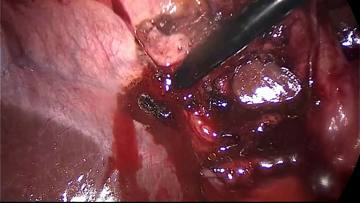
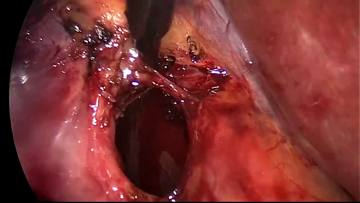
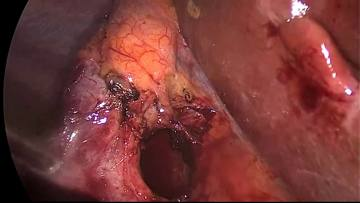
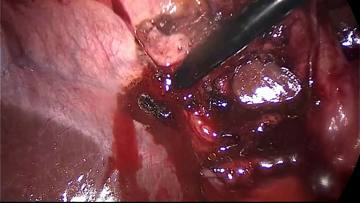
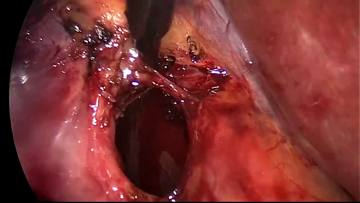
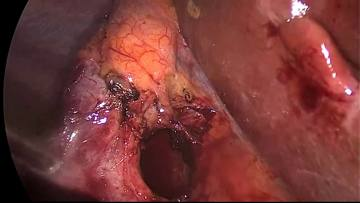
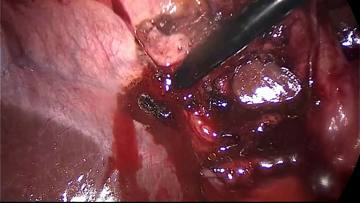
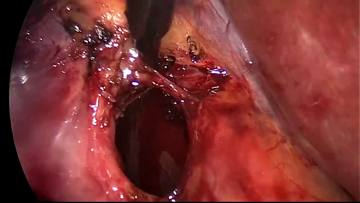
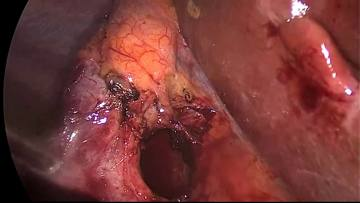
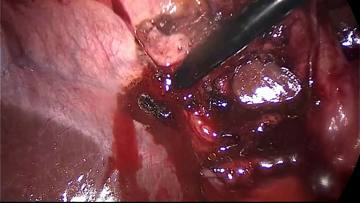
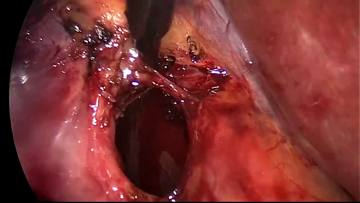
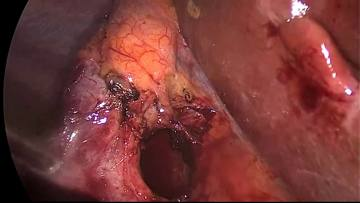
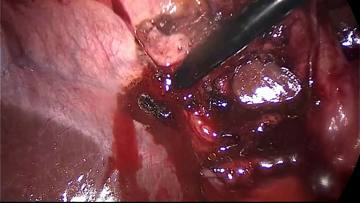
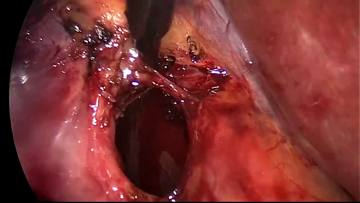
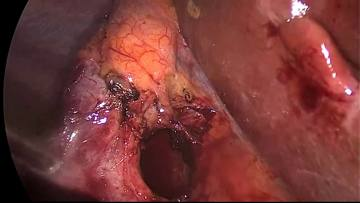
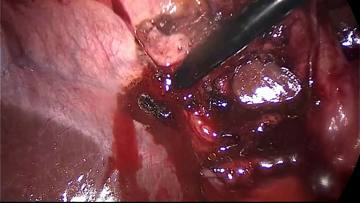
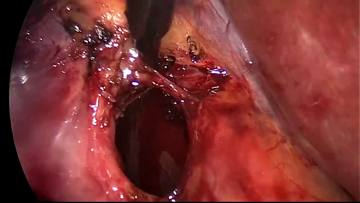
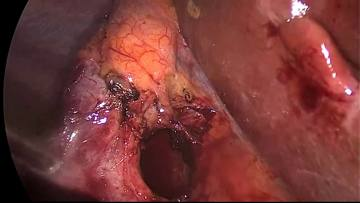
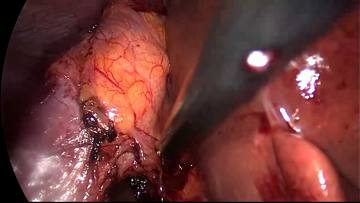
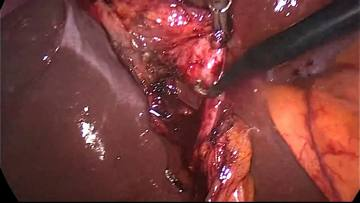
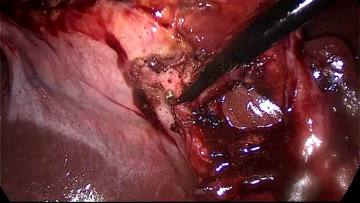
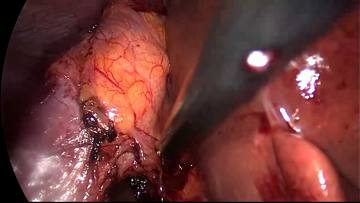
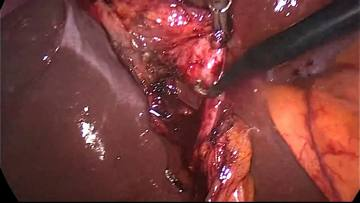
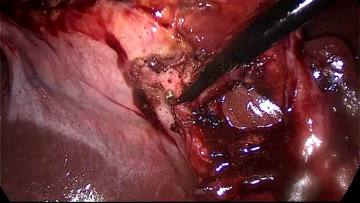
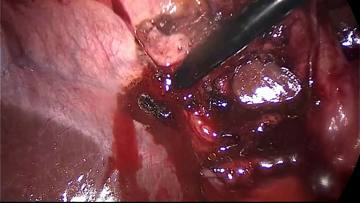
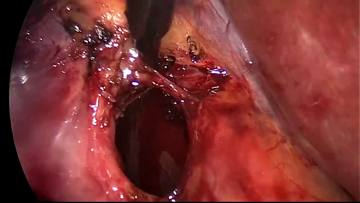
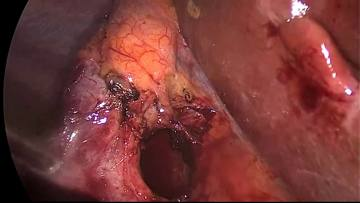
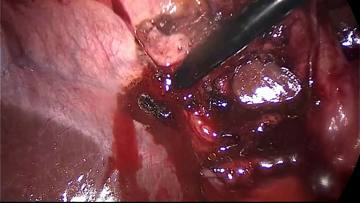
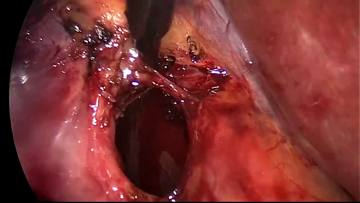
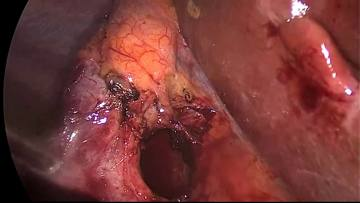
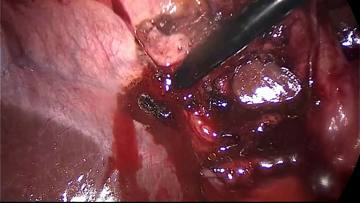
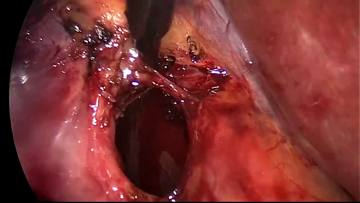
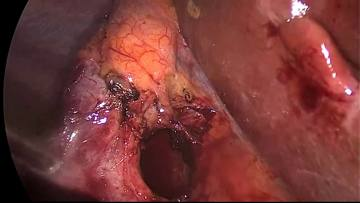
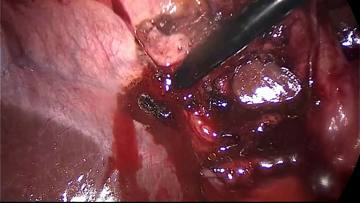
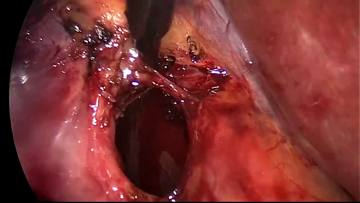
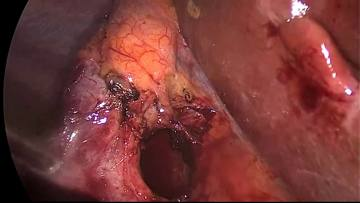
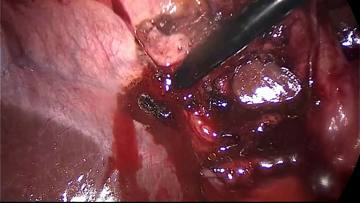
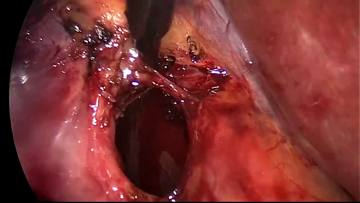
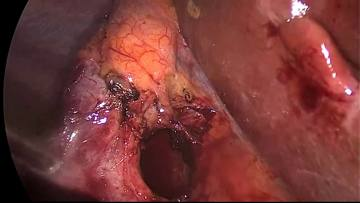
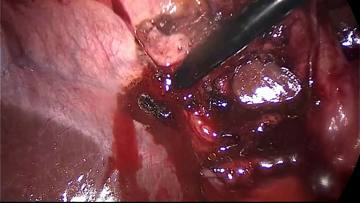
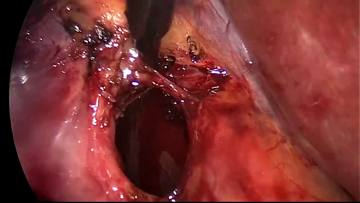
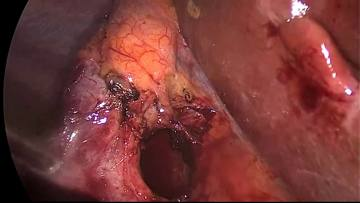
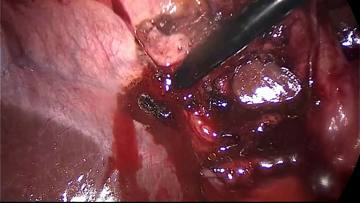
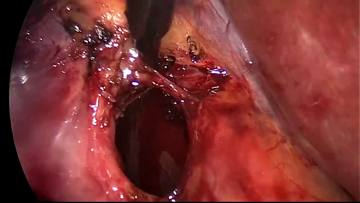
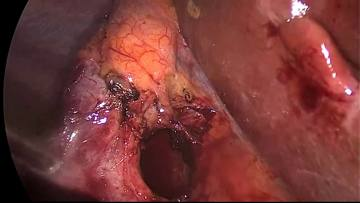
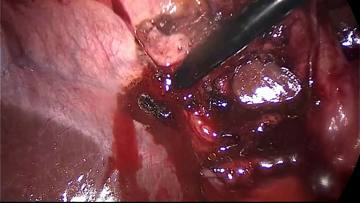
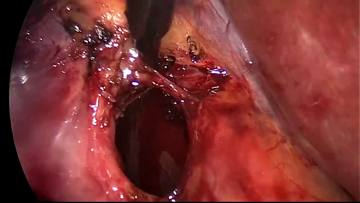
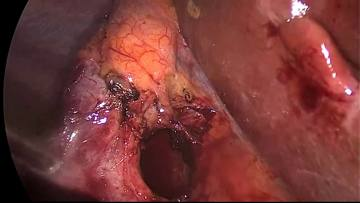
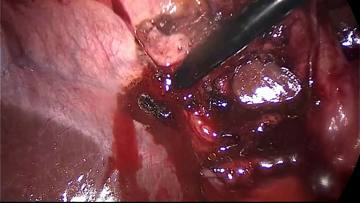
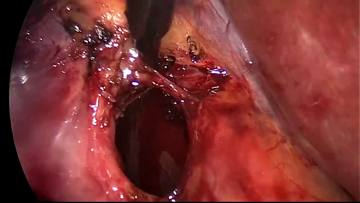
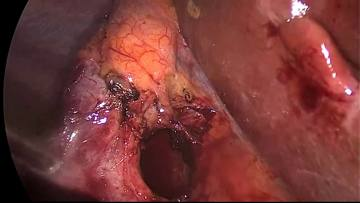
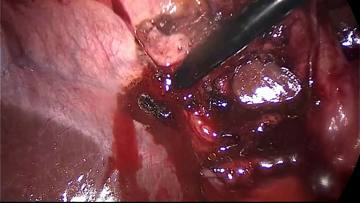
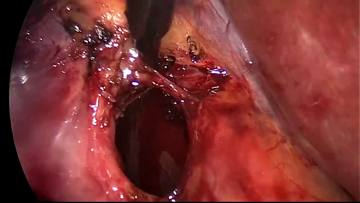
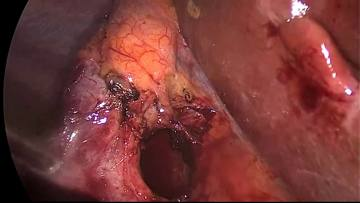

In [8]:
# HTML example browser by judge score
from IPython.display import HTML, display
import base64
import html
import json
import io

EXAMPLES_PER_SCORE_PER_METHOD = 2
EXAMPLE_CANDIDATES = ['extracted_json', 'original_text']
EXAMPLE_SCORE_ORDER = [0.0, 0.5, 1.0]

records_by_id = {record['example_id']: record for record in records}
gt_by_id = {record['example_id']: convert_record_to_simple_actions(record) for record in records}


def _escape(value):
    return html.escape(str(value if value is not None else ''))


def _json_block(value):
    return _escape(json.dumps(value, indent=2, sort_keys=True))


def _frame_path(video_id, frame_id):
    frame_dir = FRAMES_DIR / str(video_id)
    candidates = [
        frame_dir / f'frame_{int(frame_id):06d}.png',
        frame_dir / f'frame_{int(frame_id):06d}.jpg',
        frame_dir / f'frame_{int(frame_id):06d}.jpeg',
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    if frame_dir.exists():
        existing = sorted(frame_dir.glob('frame_*.*'))
        if existing:
            def frame_number(path):
                try:
                    return int(path.stem.split('_')[-1])
                except Exception:
                    return 10**12
            return min(existing, key=lambda path: abs(frame_number(path) - int(frame_id)))
    return None


def _image_data_uri(path, max_size=(360, 220), quality=72):
    if path is None or not path.exists():
        return None
    try:
        from PIL import Image
        with Image.open(path) as img:
            img.thumbnail(max_size)
            if img.mode not in {'RGB', 'L'}:
                img = img.convert('RGB')
            buf = io.BytesIO()
            img.save(buf, format='JPEG', quality=quality, optimize=True)
            data = base64.b64encode(buf.getvalue()).decode('ascii')
            return f'data:image/jpeg;base64,{data}'
    except Exception:
        suffix = path.suffix.lower().lstrip('.') or 'png'
        mime = 'jpeg' if suffix in {'jpg', 'jpeg'} else suffix
        data = base64.b64encode(path.read_bytes()).decode('ascii')
        return f'data:image/{mime};base64,{data}'


def _review_frames(record):
    coarse = record.get('coarse', {})
    start = int(coarse.get('start_frame', 0))
    end = int(coarse.get('end_frame', start))
    mid = int(coarse.get('mid_frame', (start + end) // 2))
    seen = set()
    frames = []
    for label, frame_id in [('start', start), ('mid', mid), ('end', end)]:
        if frame_id in seen:
            continue
        seen.add(frame_id)
        frames.append((label, frame_id))
    return frames


def _frames_html(record):
    video_id = record.get('video_id')
    parts = []
    for label, frame_id in _review_frames(record):
        path = _frame_path(video_id, frame_id)
        uri = _image_data_uri(path)
        if uri:
            parts.append(
                '<figure class="score-example-frame">'
                f'<img src="{uri}" alt="{_escape(label)} frame {int(frame_id)}">'
                f'<figcaption>{_escape(label)} &middot; frame {int(frame_id)}</figcaption>'
                '</figure>'
            )
        else:
            parts.append(
                '<figure class="score-example-frame missing">'
                f'<div>Missing frame {int(frame_id)}</div>'
                f'<figcaption>{_escape(label)}</figcaption>'
                '</figure>'
            )
    return '<div class="score-example-frames">' + ''.join(parts) + '</div>'


def _maybe_parse_json(value):
    if not isinstance(value, str):
        return value
    text = value.strip()
    if not text or text[0] not in '[{':
        return value
    try:
        return json.loads(text)
    except Exception:
        try:
            return extract_json_object(text)
        except Exception:
            return value


def _extracted_natural_payload(item):
    if item.get('extracted_actions_natural_language'):
        return _maybe_parse_json(item.get('extracted_actions_natural_language'))
    return naturalize_simple_actions(_maybe_parse_json(item.get('extracted_actions', {})))


def _extracted_judge_payload(item):
    return _maybe_parse_json(item.get('extracted_actions', {}))


def _evaluated_candidate_payload(item, candidate_kind):
    if candidate_kind == 'extracted_json':
        return _extracted_judge_payload(item)
    return _maybe_parse_json(item.get('segmentation_answer', ''))


def _original_candidate_payload(item):
    return _maybe_parse_json(item.get('segmentation_answer', ''))


def _extracted_code_payload(item):
    return _maybe_parse_json(item.get('extracted_actions', {}))


def _judge_for_candidate(item, candidate_kind):
    if candidate_kind == 'extracted_json':
        return item.get('extracted_llm_judge', {})
    return item.get('original_llm_judge', {})


def collect_score_examples(results, max_per_score_per_method=EXAMPLES_PER_SCORE_PER_METHOD):
    selected = {score: {method: [] for method in METHODS} for score in EXAMPLE_SCORE_ORDER}
    for item in results:
        if item.get('status') != 'ok':
            continue
        method = item.get('method')
        if method not in METHODS:
            continue
        record = records_by_id.get(item.get('example_id'))
        gt = gt_by_id.get(item.get('example_id'))
        if record is None or gt is None:
            continue
        for candidate_kind in EXAMPLE_CANDIDATES:
            judge = _judge_for_candidate(item, candidate_kind)
            for rubric in judge.get('rubric', []):
                try:
                    score = float(rubric.get('score'))
                except Exception:
                    continue
                if score not in selected:
                    continue
                bucket = selected[score].setdefault(method, [])
                if len(bucket) >= max_per_score_per_method:
                    continue
                bucket.append({
                    'item': item,
                    'record': record,
                    'gt': gt,
                    'candidate_kind': candidate_kind,
                    'rubric': rubric,
                    'score': score,
                })
    return selected


def render_score_examples(score_examples):
    style = """
    <style>
      .score-example-root {font-family: system-ui, -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif; color: #1f2933;}
      .score-example-root h3 {margin: 0 0 8px; font-size: 20px;}
      .score-example-section {margin: 18px 0 26px;}
      .score-example-section h4 {margin: 0 0 10px; font-size: 16px;}
      .score-example-method {margin: 14px 0 18px;}
      .score-example-method h5 {margin: 0 0 8px; font-size: 14px;}
      .score-example-card {border: 1px solid #d8dee4; border-radius: 8px; margin: 12px 0; padding: 12px; background: #fff;}
      .score-example-meta {display: flex; flex-wrap: wrap; gap: 8px 14px; font-size: 13px; margin-bottom: 10px;}
      .score-example-meta code {background: #f6f8fa; padding: 1px 4px; border-radius: 4px;}
      .score-example-frames {display: grid; grid-template-columns: repeat(auto-fit, minmax(180px, 1fr)); gap: 10px; margin: 10px 0;}
      .score-example-frame {margin: 0; border: 1px solid #e5e7eb; border-radius: 6px; overflow: hidden; background: #f8fafc;}
      .score-example-frame img {display: block; width: 100%; height: 150px; object-fit: contain; background: #111827;}
      .score-example-frame.missing div {height: 150px; display: flex; align-items: center; justify-content: center; color: #6b7280;}
      .score-example-frame figcaption {font-size: 12px; padding: 5px 7px; color: #4b5563;}
      .score-example-columns {display: grid; grid-template-columns: repeat(auto-fit, minmax(260px, 1fr)); gap: 10px;}
      .score-example-wide {grid-column: 1 / -1;}
      .score-example-panel {border: 1px solid #e5e7eb; border-radius: 6px; padding: 8px; background: #fbfdff; min-width: 0;}
      .score-example-panel h5 {margin: 0 0 6px; font-size: 13px;}
      .score-example-panel pre {white-space: pre-wrap; overflow-wrap: anywhere; max-height: 260px; overflow: auto; margin: 0; font-size: 12px; line-height: 1.35;}
      .score-example-rationale {font-size: 13px; line-height: 1.4; margin: 8px 0 0; padding: 8px; background: #f6f8fa; border-radius: 6px;}
    </style>
    """
    labels = {0.0: 'Errors (score 0.0)', 0.5: 'Partial matches (score 0.5)', 1.0: 'Correct matches (score 1.0)'}
    chunks = [style, '<div class="score-example-root"><h3>Judge examples by score with frames</h3>']
    for score in EXAMPLE_SCORE_ORDER:
        examples_by_method = score_examples.get(score, {})
        chunks.append(f'<section class="score-example-section"><h4>{_escape(labels.get(score, f"Score {score:g}"))}</h4>')
        if not any(examples_by_method.get(method) for method in METHODS):
            chunks.append('<p><em>No examples found for this score.</em></p></section>')
            continue
        for method_name in METHODS:
            examples = examples_by_method.get(method_name, [])
            chunks.append(f'<div class="score-example-method"><h5>Method: <code>{_escape(method_name)}</code></h5>')
            if not examples:
                chunks.append('<p><em>No examples found for this method and score.</em></p></div>')
                continue
            for example in examples:
                item = example['item']
                record = example['record']
                rubric = example['rubric']
                candidate_kind = example['candidate_kind']
                chunks.append('<article class="score-example-card">')
                chunks.append(
                    '<div class="score-example-meta">'
                    f'<span><b>example</b> <code>{_escape(item.get("example_id"))}</code></span>'
                    f'<span><b>video</b> <code>{_escape(item.get("video_id"))}</code></span>'
                    f'<span><b>criterion</b> {_escape(item.get("criterion"))}</span>'
                    f'<span><b>method</b> {_escape(item.get("method"))}</span>'
                    f'<span><b>candidate</b> {_escape(candidate_label(candidate_kind))}</span>'
                    f'<span><b>rubric</b> {_escape(rubric.get("item"))}</span>'
                    f'<span><b>score</b> {score:g}</span>'
                    '</div>'
                )
                chunks.append(_frames_html(record))
                evaluated_label = candidate_label(candidate_kind)
                chunks.append('<div class="score-example-columns">')
                chunks.append(f'<div class="score-example-panel score-example-wide"><h5>Ground truth simple actions</h5><pre>{_json_block(example["gt"])}</pre></div>')
                chunks.append(f'<div class="score-example-panel"><h5>Evaluated candidate: {_escape(evaluated_label)}</h5><pre>{_json_block(_evaluated_candidate_payload(item, candidate_kind))}</pre></div>')
                chunks.append(f'<div class="score-example-panel"><h5>Original segmentation output</h5><pre>{_json_block(_original_candidate_payload(item))}</pre></div>')
                chunks.append(f'<div class="score-example-panel"><h5>Extracted code JSON used for LLM judge/comparison</h5><pre>{_json_block(_extracted_judge_payload(item))}</pre></div>')
                chunks.append(f'<div class="score-example-panel"><h5>Extracted code JSON used for spec eval</h5><pre>{_json_block(_extracted_code_payload(item))}</pre></div>')
                chunks.append('</div>')
                chunks.append(f'<div class="score-example-rationale"><b>Rationale:</b> {_escape(rubric.get("rationale", ""))}</div>')
                chunks.append('</article>')
            chunks.append('</div>')
        chunks.append('</section>')
    chunks.append('</div>')
    return ''.join(chunks)


score_examples = collect_score_examples(ok_results)
display(HTML(render_score_examples(score_examples)))
